# 09 · Generative Adversarial Network (GAN)

The VAE (notebook 08) generates by maximizing a likelihood-style objective. A **GAN** takes a different route: a *game* between two networks.

- The **generator** $G$ turns random noise $z$ into a fake sample $G(z)$.
- The **discriminator** $D$ looks at a sample and outputs the probability that it is *real* (from the data) rather than fake.

$G$ never sees real data directly. It improves only through the gradient of $D$'s judgment. The original minimax game:
$$\min_G\max_D\;\; \mathbb E_{x\sim p_{\text{data}}}[\log D(x)] + \mathbb E_{z\sim p(z)}[\log(1-D(G(z)))]$$

**Discriminator step** — ordinary binary classification: real → 1, fake → 0. With logits $\ell=D(\cdot)$ the gradient at the logits is $(\sigma(\ell)-\text{label})/N$.

**Generator step** — the minimax form $\log(1-D(G(z)))$ has vanishing gradients early on (when $D$ easily spots fakes, $D(G(z))\approx0$ and the loss is flat). The standard fix is the **non-saturating loss**: instead *maximize* $\log D(G(z))$, i.e. minimize $-\log D(G(z))=\text{softplus}(-\ell)$. Its gradient at the logits is $(\sigma(\ell)-1)/N$.

The generator gradient has to flow **backward through $D$ into $G$**: $\frac{\partial L_G}{\partial\theta_G}=\frac{\partial L_G}{\partial \ell}\cdot\frac{\partial \ell}{\partial G(z)}\cdot\frac{\partial G(z)}{\partial\theta_G}$. We run $D$'s backward pass only to get $\partial\ell/\partial G(z)$, and **don't apply** $D$'s weight gradients in this step.

**Why GANs are hard:** there's no single loss that decreases, the two networks chase each other, and $G$ can "mode collapse" onto a few outputs that fool $D$. So we measure sample quality *and* coverage, not just loss.

## The data
Same task as notebook 08: 12×12 images of a Gaussian blob whose centre $(c_x,c_y)$ is the only hidden factor. Two numbers describe every image, so we can check both whether samples **look like blobs** and whether they **cover all positions**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

real data: (4000, 144)  (each image is 12x12 = 144 pixels)


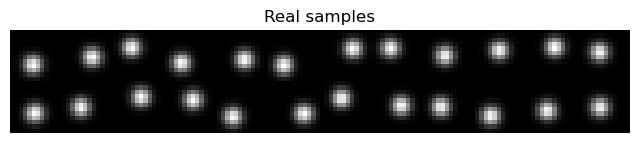

In [2]:
SIZE = 12
yy, xx = np.mgrid[0:SIZE, 0:SIZE]


def render(cx, cy, sigma=1.5):
    """Gaussian blobs centred at (cx, cy); returns (n, SIZE, SIZE) with values in [0, 1]."""
    cx, cy = np.atleast_1d(cx), np.atleast_1d(cy)
    return np.exp(-((xx[None] - cx[:, None, None]) ** 2 + (yy[None] - cy[:, None, None]) ** 2) / (2 * sigma ** 2))


def make_dataset(n, seed):
    rng = np.random.RandomState(seed)
    centres = rng.uniform(3, 8, (n, 2))
    return render(centres[:, 0], centres[:, 1]).reshape(n, -1), centres


def show_grid(imgs, rows, cols, title=None, ax=None):
    mosaic = imgs.reshape(rows, cols, SIZE, SIZE).transpose(0, 2, 1, 3).reshape(rows * SIZE, cols * SIZE)
    ax = ax or plt.gca()
    ax.imshow(mosaic, cmap="gray", vmin=0, vmax=1); ax.set_title(title); ax.axis("off")


X_train, C_train = make_dataset(4000, seed=42)
print(f"real data: {X_train.shape}  (each image is {SIZE}x{SIZE} = {SIZE*SIZE} pixels)")
plt.figure(figsize=(8, 2.4)); show_grid(X_train[:24], 2, 12, "Real samples"); plt.show()

## Building blocks
`Dense` layers keep their gradients in preallocated arrays (overwritten on every `backward`), so an optimizer can hold `(param, grad)` pairs. Because the arrays are overwritten, running $D$'s backward pass during the generator step is harmless as long as we simply don't call $D$'s optimizer there.

The generator uses ReLU and ends in a sigmoid (pixels in $[0,1]$). The discriminator uses **LeakyReLU** (a small negative slope), which keeps gradients alive for negative inputs — standard for GAN discriminators.

In [3]:
class Dense:
    def __init__(self, d_in, d_out):
        self.W = np.random.randn(d_in, d_out) * np.sqrt(2.0 / d_in)
        self.b = np.zeros(d_out)
        self.dW, self.db = np.zeros_like(self.W), np.zeros_like(self.b)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW[...] = self.x.T @ dout
        self.db[...] = dout.sum(axis=0)
        return dout @ self.W.T


class MLP:
    """Dense layers with a hidden activation in between (ReLU or LeakyReLU); last layer linear."""

    def __init__(self, sizes, slope=0.0):
        self.layers = [Dense(a, b) for a, b in zip(sizes[:-1], sizes[1:])]
        self.slope = slope                  # 0 -> ReLU, 0.2 -> LeakyReLU

    def forward(self, x):
        self.pre = []
        for i, layer in enumerate(self.layers):
            x = layer.forward(x)
            if i < len(self.layers) - 1:
                self.pre.append(x)
                x = np.where(x > 0, x, self.slope * x)
        return x

    def backward(self, dout):
        for i in reversed(range(len(self.layers))):
            if i < len(self.layers) - 1:
                dout = dout * np.where(self.pre[i] > 0, 1.0, self.slope)
            dout = self.layers[i].backward(dout)
        return dout

    def parameters(self):
        return [(p, g) for l in self.layers for p, g in ((l.W, l.dW), (l.b, l.db))]


class Adam:
    def __init__(self, pairs, lr=2e-4, b1=0.5, b2=0.999, eps=1e-8):    # b1=0.5 is the usual GAN choice
        self.pairs, self.lr, self.b1, self.b2, self.eps, self.t = pairs, lr, b1, b2, eps, 0
        self.m = [np.zeros_like(p) for p, _ in pairs]
        self.v = [np.zeros_like(p) for p, _ in pairs]

    def step(self):
        self.t += 1
        for i, (p, g) in enumerate(self.pairs):
            self.m[i] = self.b1 * self.m[i] + (1 - self.b1) * g
            self.v[i] = self.b2 * self.v[i] + (1 - self.b2) * g ** 2
            p -= self.lr * (self.m[i] / (1 - self.b1 ** self.t)) / (np.sqrt(self.v[i] / (1 - self.b2 ** self.t)) + self.eps)


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def softplus(z):
    return np.logaddexp(0, z)               # stable log(1 + e^z)

## Generator and discriminator
`Generator.backward` receives the gradient with respect to the generated *image* (that is what flows back out of $D$) and pushes it through the sigmoid and the layers.

In [4]:
class Generator:
    def __init__(self, d_latent, d_hidden, d_out):
        self.net = MLP([d_latent, d_hidden, d_out], slope=0.0)

    def forward(self, z):
        self.img = sigmoid(self.net.forward(z))
        return self.img

    def backward(self, dimg):
        return self.net.backward(dimg * self.img * (1 - self.img))      # sigmoid'(l) = s(1-s)

    def parameters(self):
        return self.net.parameters()


class Discriminator:
    def __init__(self, d_in, d_hidden):
        self.net = MLP([d_in, d_hidden, 1], slope=0.2)

    def forward(self, x):                   # returns logits, shape (N, 1)
        return self.net.forward(x)

    def backward(self, dlogit):             # returns grad w.r.t. the input images
        return self.net.backward(dlogit)

    def parameters(self):
        return self.net.parameters()

## The two losses
- `d_loss_and_backward`: real and fake images stacked into one batch with labels 1/0; mean binary cross-entropy. Gradient at the logits is $(\sigma(\ell)-y)/N$.
- `g_loss_and_backward`: non-saturating loss $\text{mean}[\text{softplus}(-\ell)]$ on $D(G(z))$. Gradient at the logits is $(\sigma(\ell)-1)/N$, then back through $D$ (input gradient only) and into $G$.

In [5]:
def d_loss_and_backward(D, real, fake):
    x = np.vstack([real, fake])
    y = np.r_[np.ones(len(real)), np.zeros(len(fake))][:, None]
    logits = D.forward(x)
    loss = np.mean(softplus(-logits) * y + softplus(logits) * (1 - y))      # BCE with logits
    D.backward((sigmoid(logits) - y) / len(x))
    return loss


def g_loss_and_backward(G, D, z):
    fake = G.forward(z)
    logits = D.forward(fake)
    loss = np.mean(softplus(-logits))                                       # -log D(G(z))
    dfake = D.backward((sigmoid(logits) - 1) / len(z))                      # D's weight grads are computed but NOT applied
    G.backward(dfake)
    return loss

## Verify both backward paths against finite differences
The discriminator check is routine. The generator check is the important one: it confirms the gradient survives the trip *through $D$* into $G$'s weights. (Leaky-ReLU kinks are measure-zero, so random points are fine.)

In [6]:
def grad_check(loss_fn, pairs, samples_per_param=3, eps=1e-5, seed=0):
    """Worst relative error between analytic grads and central finite differences."""
    rng = np.random.RandomState(seed)
    worst = 0.0
    pairs = [(p, g.copy()) for p, g in pairs]       # snapshot: loss_fn may run backward and overwrite the live grad arrays
    for p, g in pairs:
        for _ in range(samples_per_param):
            idx = tuple(rng.randint(0, s) for s in p.shape)
            orig = p[idx]
            p[idx] = orig + eps; lp = loss_fn()
            p[idx] = orig - eps; lm = loss_fn()
            p[idx] = orig
            num = (lp - lm) / (2 * eps)
            worst = max(worst, abs(num - g[idx]) / (abs(num) + abs(g[idx]) + 1e-6))
    return worst


np.random.seed(0)
Gc, Dc = Generator(2, 16, SIZE * SIZE), Discriminator(SIZE * SIZE, 16)
real_c, fake_c, z_c = X_train[:4], X_train[4:8], np.random.randn(4, 2)

d_loss_and_backward(Dc, real_c, fake_c)
err_d = grad_check(lambda: d_loss_and_backward(Dc, real_c, fake_c), Dc.parameters())

g_loss_and_backward(Gc, Dc, z_c)
err_g = grad_check(lambda: g_loss_and_backward(Gc, Dc, z_c), Gc.parameters())
print(f"discriminator grads: worst relative error {err_d:.2e}")
print(f"generator grads (through D): worst relative error {err_g:.2e}")
assert err_d < 1e-5 and err_g < 1e-5, "backward pass disagrees with finite differences"

discriminator grads: worst relative error 6.80e-09
generator grads (through D): worst relative error 8.12e-09


## Training
Each step: (1) one $D$ update on a real batch plus a fresh fake batch; (2) one $G$ update. We log both losses and the mean $D$ output on real and fake samples. In a healthy game $D(\text{real})$ stays above $D(\text{fake})$ but they stay **near 0.5**; if $D$ wins completely ($D(\text{fake})\to0$), $G$ stops learning.

In [7]:
Z_DIM, HIDDEN, BATCH, STEPS = 8, 128, 64, 6000

np.random.seed(1)
G = Generator(Z_DIM, HIDDEN, SIZE * SIZE)
D = Discriminator(SIZE * SIZE, HIDDEN)
opt_g, opt_d = Adam(G.parameters()), Adam(D.parameters())
rng = np.random.RandomState(0)

log = []
for step in range(STEPS):
    real = X_train[rng.randint(0, len(X_train), BATCH)]

    fake = G.forward(rng.randn(BATCH, Z_DIM))
    d_loss = d_loss_and_backward(D, real, fake)          # D step (fake is a constant here)
    opt_d.step()

    g_loss = g_loss_and_backward(G, D, rng.randn(BATCH, Z_DIM))     # G step
    opt_g.step()

    if step % 20 == 0:
        d_real = sigmoid(D.forward(real)).mean()
        d_fake = sigmoid(D.forward(G.forward(rng.randn(BATCH, Z_DIM)))).mean()
        log.append((step, d_loss, g_loss, d_real, d_fake))
    if step % 1500 == 0:
        print(f"step {step:>5}  D loss {d_loss:.3f}  G loss {g_loss:.3f}  D(real) {log[-1][3]:.2f}  D(fake) {log[-1][4]:.2f}")
log = np.array(log)

step     0  D loss 0.740  G loss 0.663  D(real) 0.51  D(fake) 0.53


step  1500  D loss 0.665  G loss 0.892  D(real) 0.50  D(fake) 0.44


step  3000  D loss 0.561  G loss 0.849  D(real) 0.58  D(fake) 0.44


step  4500  D loss 0.585  G loss 0.808  D(real) 0.56  D(fake) 0.45


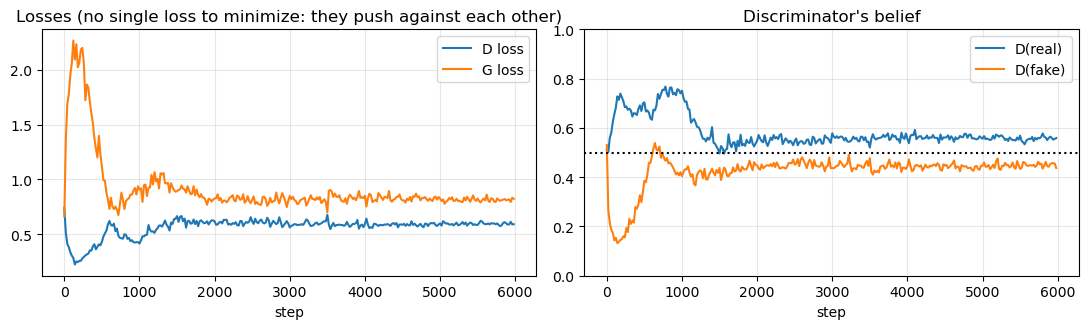

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(log[:, 0], log[:, 1], label="D loss"); axes[0].plot(log[:, 0], log[:, 2], label="G loss")
axes[0].set(title="Losses (no single loss to minimize: they push against each other)", xlabel="step"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(log[:, 0], log[:, 3], label="D(real)"); axes[1].plot(log[:, 0], log[:, 4], label="D(fake)")
axes[1].axhline(0.5, color="k", ls=":"); axes[1].set(title="Discriminator's belief", xlabel="step", ylim=(0, 1)); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Did it work?
Two separate questions, because a GAN can fail either way:
1. **Quality** — does each sample look like a real blob? We fit a blob to every generated image (centre of mass, best amplitude) and measure how much of the image the fit leaves unexplained.
2. **Coverage** — do the samples cover *all* blob positions? A collapsed generator would produce a few positions repeatedly. We bin the fitted centres into a 5×5 grid over the real range and count occupied cells.

In [9]:
def fit_blob(imgs):
    """Return fitted centres and the fraction of image energy NOT explained by a single Gaussian blob (0 = perfect)."""
    m = imgs.reshape(len(imgs), SIZE, SIZE)
    mass = m.sum(axis=(1, 2)) + 1e-9
    cx, cy = (m * xx).sum(axis=(1, 2)) / mass, (m * yy).sum(axis=(1, 2)) / mass
    ref = render(cx, cy).reshape(len(imgs), -1)
    amp = (imgs * ref).sum(axis=1) / ((ref * ref).sum(axis=1) + 1e-9)
    resid = ((imgs - amp[:, None] * ref) ** 2).sum(axis=1) / ((imgs ** 2).sum(axis=1) + 1e-9)
    return np.c_[cx, cy], resid


def evaluate(imgs):
    centres, resid = fit_blob(imgs)
    clean = (resid < 0.1) & (imgs.max(axis=1) > 0.5)
    inside = clean & (centres >= 3).all(axis=1) & (centres <= 8).all(axis=1)
    cells = np.floor((np.clip(centres[inside], 3, 8 - 1e-9) - 3) / 1.0).astype(int)
    covered = len({tuple(c) for c in cells})
    return clean.mean(), covered / 25, centres[clean]


G_samples = G.forward(np.random.RandomState(5).randn(1000, Z_DIM))
quality, coverage, gen_centres = evaluate(G_samples)
q_real, cov_real, _ = evaluate(X_train[:1000])
print(f"{'':<12}{'clean blobs':<14}{'grid cells covered (of 25)'}")
print(f"{'real data':<12}{q_real:<14.0%}{cov_real * 25:.0f}")
print(f"{'GAN':<12}{quality:<14.0%}{coverage * 25:.0f}")

assert quality > 0.8, "GAN samples should mostly look like blobs"
assert coverage > 0.7, "GAN collapsed onto too few blob positions (mode collapse)"

            clean blobs   grid cells covered (of 25)
real data   100%          25
GAN         99%           25


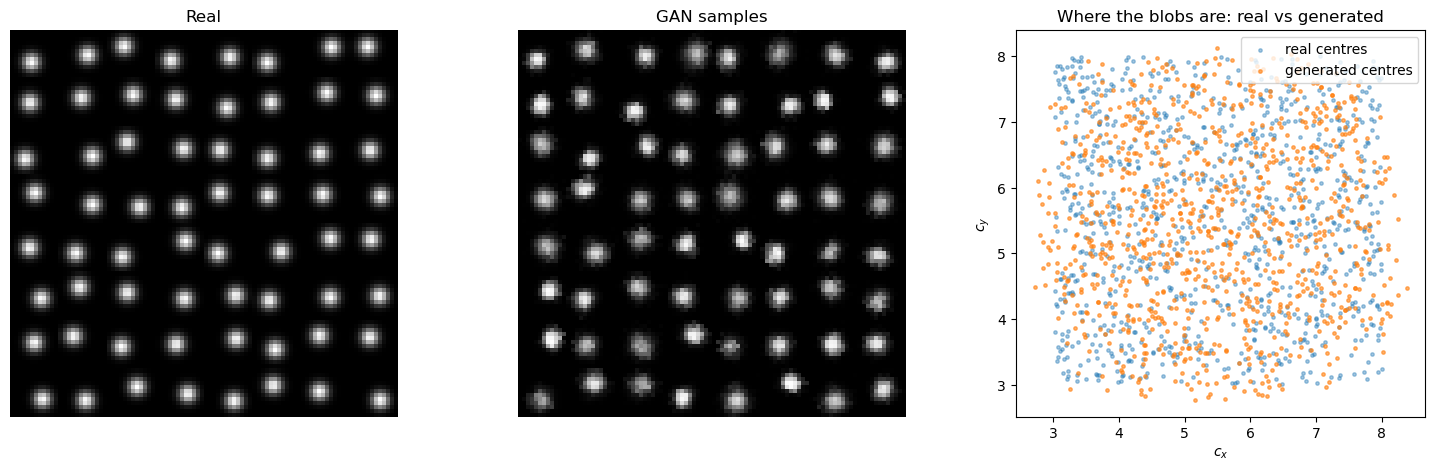

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
show_grid(X_train[:64], 8, 8, "Real", axes[0])
show_grid(G_samples[:64], 8, 8, "GAN samples", axes[1])
axes[2].scatter(*C_train[:1000].T, s=6, alpha=0.4, label="real centres")
axes[2].scatter(*gen_centres[:1000].T, s=6, alpha=0.6, label="generated centres")
axes[2].set(title="Where the blobs are: real vs generated", xlabel="$c_x$", ylabel="$c_y$", aspect="equal"); axes[2].legend(loc="upper right")
plt.tight_layout(); plt.show()

### The latent space
With `Z_DIM = 8` the noise has more dimensions than the 2 hidden factors, so the generator has to learn to *ignore* the extras. Below: walking along a straight line between two random noise vectors. A well-behaved generator moves the blob smoothly.

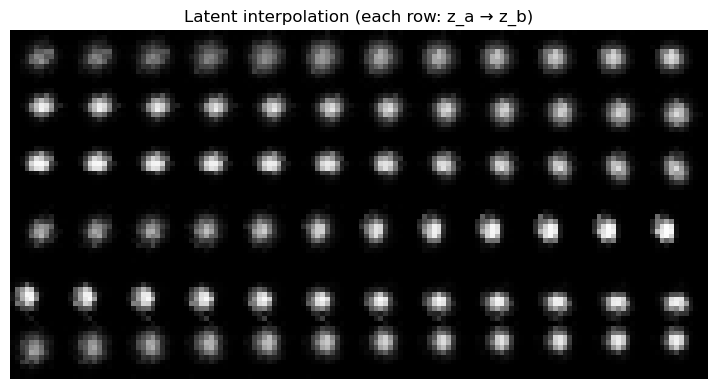

In [11]:
r = np.random.RandomState(3)
rows = []
for _ in range(6):
    a, b = r.randn(Z_DIM), r.randn(Z_DIM)
    rows.append(G.forward(np.array([(1 - t) * a + t * b for t in np.linspace(0, 1, 12)])))
plt.figure(figsize=(9, 4.6)); show_grid(np.vstack(rows), 6, 12, "Latent interpolation (each row: z_a → z_b)"); plt.show()

## Takeaways
- Training is a **two-player game**: neither loss converges to a minimum, and D(real)/D(fake) hovering near 0.5 is the healthy sign.
- The **non-saturating** generator loss gives useful gradients even when $D$ is winning early.
- The generator's gradient reaches its weights only **through the discriminator**. The finite-difference check confirms that path.
- Judge a GAN on **quality and coverage**, since loss curves say little. A collapsed generator can have a perfect-looking loss.
- Compared to the VAE (08): GAN samples are typically sharper but training is touchier, and there's no encoder or likelihood, so no reconstruction and no direct way to score a sample.

Things to try: change `Z_DIM`, `HIDDEN` or the learning rate and watch D(fake); train D twice per G step; or remove LeakyReLU and see how the game changes.

**Next**: word embeddings (`10`), residual networks (`11`), an autograd engine (`12`).